# EOD assignment, 2-fish recording: two sets of conductivities, all EODs

Recording `2024-02-13T14_33_21` (`data/2_fish_silent`); fish 0 (the smaller fish) is silenced, so **the larger fish (fish 1) is the
emitter** and every EOD should go to fish 1. Same model-pattern assignment as `EOD_assignment_3_fish_conductivities.ipynb`
(patterns scaled to max |v| = 1, **the model's sign fixed**: model × −1, see section 4), with this recording's electrode file
(`electrodes_signed_px_coord_2-fish.csv`), on **all 18,770 EODs** of the recording, for

- two sets of conductivities (`MATS`): the previous one, and the one of the BEM model of *G. petersii* (`GPetersii10lf.con`,
  `Dos_peces_CILI_paralelo_all.esc`: water 1e-4 S/cm, body 0.01 S/cm, skin 0.001 S/cm²), with a 0.005 cm skin;
- two sink positions along the emitter's midline (`SINKS`): at the tail tip, and 5% of the body length from it.

Accuracy (% of EODs assigned to fish 1) is reported as in Denis' notebook (`../EODAssignment/analysis/notebooks/2fish-silent-assign-eods.ipynb`),
for all EODs and for the EODs in good frames, next to Denis' latest run on the same EODs.

1. **Data**: EODs, ZEUS masks, electrodes, frame groups.
2. **Conductivities**: the two sets, and the field of one example EOD with each.
3. **Model voltages** of every EOD, for both sets and both sinks.
4. **Results**: % correct per frame group, per fish, against the distance between the fish.
5. **Summary**.

Frame groups come from `EOD_assignment_2_fish_silent.ipynb` (`QC`) and Denis' run; everything new is saved in `OUT`.

In [1]:
import os, pickle, hashlib, json
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.spatial import cKDTree
from compute_electric_field import (theta_outer, mask_to_grid, multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential,
                                    unflatten_to_grid, gammas)
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, pair_voltages, compare_patterns, model_cache_tag, candidate_field

DATA = 'data/2_fish_silent'
EOD_CSV = f'{DATA}/Data_1fish_2024-02-13T14_33_21.csv'
TRACK_PKL = f'{DATA}/elephantnose_20240213T143321_tracking_final.pkl'
ELECTRODES_CSV = 'data/electrodes/electrodes_signed_px_coord_2-fish.csv'   # this recording's electrode file
QC = 'results/eod_ground_truth'                                            # outputs of EOD_assignment_2_fish_silent.ipynb
DENIS_CSV = 'results/eod_assignment_2_fish_silent/eod_assignment_summary.csv'   # Denis' latest run (2-fish electrodes, no refractory)
OUT = f'{QC}/conductivities'
os.makedirs(f'{OUT}/figures', exist_ok=True)

FISH, EMITTER = (0, 1), 1                       # ZEUS labels: 0 = smaller fish (silent), 1 = larger fish = the emitter
FISH_NAME = {0: 'fish 0 (smaller, silent)', 1: 'fish 1 (larger, emitter)'}
FISH_COLOR = {0: '#2E8B57', 1: '#D45087'}
PX_PER_CM = 912 / 60                            # tank side: 912 px = 60 cm (Denis' pixel2cm)

# field model (as in EOD_assignment_3_fish_conductivities.ipynb)
N = 150                                         # tank grid resolution (N x N)
n_poles = 100                                   # n_poles + 1 point currents along each midline, tail -> head
h = 1.0 / (N - 1)                               # grid spacing (tank side = 1)
SINKS = (0.0, 0.05)                             # sink position: fraction of the body length from the tail tip
SINK_NAME = {0.0: 'sink at tail tip', 0.05: 'sink 5% from tail tip'}
CELL_CM = (912 - 1) / (N - 1) / PX_PER_CM       # grid spacing in cm: tank coords [0, 1] = P - 1 px
SKIN_CM = 0.005                                 # skin thickness of the BEM set (cm)
LAMBDA_CM = 1e-4 / 1e-3                         # CondMedio / CondPiel: the BEM skin costs as much as 0.1 cm of water
MATS = {                                        # conductivities relative to water (omega = 0, so eps plays no role)
    'previous': dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6),
    'bem': dict(sigma_water=1.0,      eps_water=0.0,     # CondMedio 1e-4 S/cm -> reference
                sigma_interior=100.0, eps_interior=0.0,  # CondCuerpo 0.01 / 1e-4
                sigma_skin=1 / (LAMBDA_CM / SKIN_CM + 1 / 100.0), eps_skin=0.0),   # 0.04998: CondPiel 1e-3 S/cm^2 over SKIN_CM
}
DELTA_H = {'previous': 0.5, 'bem': SKIN_CM / CELL_CM}   # skin thickness in grid cells (bem: 0.0124)
MAT_NAME = {'previous': 'previous σ (interior 200, skin 0.05, 0.2 cm)', 'bem': 'BEM σ (interior 100, skin 0.05, 0.005 cm)'}
N_WORKERS = 3                                   # parallel field solves (the 3-fish run uses the other cores)

## 1. Data

EOD table (one row per EOD: frame, time in s, SLEAP keypoints and 10 electrode pairs × the samples around the peak), ZEUS masks
(frame k of the pickle = frame k of the video = `Frame`), electrode pairs, and the frame groups used in Denis' notebook:

| group | EODs whose frame … |
|---|---|
| all EODs | any frame |
| mask-QC good | passes the ZEUS mask QC of `EOD_assignment_2_fish_silent.ipynb` (both fish pass every check) |
| SLEAP-good | is in `2_fish_good_frames_sleap.csv` (Denis' `sleap_good_frame`) |
| good frames | both (Denis' `good_frame`; the 3,532 EODs of `EOD_assignment_2_fish_silent.ipynb`) |

In [2]:
df_eod = pd.read_csv(EOD_CSV)
df_eod['RelativeTime'] = df_eod.Time                    # seconds from the start of the recording
trace_cols = {p: sorted([c for c in df_eod.columns if c.startswith(f'electrode_{p}_time_')], key=lambda c: int(c.rsplit('_', 1)[1]))
              for p in sorted({int(c.split('_')[1]) for c in df_eod.columns if c.startswith('electrode_')})}
print(f"{len(df_eod)} EODs, {len(trace_cols)} pairs x {len(trace_cols[1])} samples")

def recorded_pair_traces(row, pair_ids):
    '''(n_pairs, n_samp) recorded voltages of one df_eod row, each pair demeaned.'''
    V = np.stack([row[trace_cols[p]].to_numpy(float) for p in pair_ids])
    return V - np.nanmean(V, axis=1, keepdims=True)

with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
frames, P = trk['frames'], trk['shape'][0]

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask; remnants dropped).'''
    m = np.zeros((len(FISH), P, P), bool)
    fr = frames[k]
    for l, p, (y0, y1, x0, x1) in zip(fr['labels'], fr['masks'], fr['boxes']):
        if l in FISH: m[l, y0:y1, x0:x1] = mm.unpack_crop(p, (y0, y1, x0, x1))
    return m

pairs = load_electrode_pairs(ELECTRODES_CSV, P)        # [(pair id, + point, - point)] in (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]

qc = pd.read_csv(f'{QC}/eod_qc_status.csv', index_col='row')
denis = pd.read_csv(DENIS_CSV)
assert len(qc) == len(denis) == len(df_eod)
assert (qc.Frame.to_numpy() == df_eod.Frame.to_numpy()).all() and (denis.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()
assert (denis.good_frame.to_numpy() == (qc.in_good_frame & denis.sleap_good_frame).to_numpy()).all()   # good = mask QC and SLEAP
GROUPS = {'all EODs': np.ones(len(df_eod), bool), 'mask-QC good': qc.in_good_frame.to_numpy(),
          'SLEAP-good': denis.sleap_good_frame.to_numpy(), 'good frames': denis.good_frame.to_numpy()}
display(pd.DataFrame({'n EODs': {g: m.sum() for g, m in GROUPS.items()},
                      '% of EODs': {g: 100 * m.mean() for g, m in GROUPS.items()}}).round(2))
fish_per_frame = pd.Series([tuple(l for l in frames[int(k)]['labels'] if l in FISH) for k in df_eod.Frame])
print('EODs whose frame lacks a mask of fish:', {f: int((~fish_per_frame.apply(lambda t: f in t)).sum()) for f in FISH})

18770 EODs, 10 pairs x 25 samples


,n EODs,% of EODs
all EODs,18770,100.00
mask-QC good,12121,64.58
SLEAP-good,4430,23.60
good frames,3532,18.82


EODs whose frame lacks a mask of fish: {0: 153, 1: 5}


## 2. Conductivities

Relative to water. The other two fish are passive bodies: interior conductivity, and the skin as a sheet at the body boundary
(`build_A_shell`): an edge crossing the boundary gets, in series with the water and interior parts, the resistance
`delta_h × (1/σ_skin − 1/σ_interior)`, `delta_h` = skin thickness in grid cells. The sheet does not move the outline; only its
resistance per area, `delta_h × cell / σ_skin`, matters. The emitter is transparent. Resistive solve (ω = 0).

**BEM set.** The BEM files give water `CondMedio` = 1e-4 S/cm, body `CondCuerpo` = 0.01 S/cm (100 × water), skin `CondPiel` = 0.001
S/cm² with `EspesorPiel` = 1: a skin conductance per area of 1e-3 S/cm² (1 kΩ·cm²), i.e. the skin costs as much as
`CondMedio / CondPiel` = 0.1 cm of water. With a skin of 0.005 cm (`delta_h` = 0.005 / 0.402 = 0.0124 cells):
σ_skin = 1 / (0.1 / 0.005 + 1/100) = 0.04998 (× 1e-4 S/cm = 5e-6 S/cm; / 0.005 cm = 1e-3 S/cm²).

**Previous set.** The same σ_skin, 0.05, but over `delta_h` = 0.5 cells = 0.2 cm: 40 × more resistive (4 cm of water per crossing),
with interior 200 (the model of `EOD_assignment_2_fish_silent.ipynb`).

In [3]:
assert P == 912
skin_res = {n: DELTA_H[n] * (1 / m['sigma_skin'] - 1 / m['sigma_interior']) * CELL_CM for n, m in MATS.items()}   # cm of water
display(pd.DataFrame({n: {'σ water': m['sigma_water'], 'σ interior': m['sigma_interior'], 'σ skin': m['sigma_skin'],
                          'skin thickness (cm)': DELTA_H[n] * CELL_CM, 'delta_h (cells)': DELTA_H[n],
                          'skin = cm of water': skin_res[n]} for n, m in MATS.items()}).T.round(5))
assert np.isclose(skin_res['bem'], LAMBDA_CM)

,σ water,σ interior,σ skin,skin thickness (cm),delta_h (cells),skin = cm of water
previous,1.0,200.0,0.05000,0.20112,0.50000,4.02142
bem,1.0,100.0,0.04998,0.00500,0.01243,0.10000


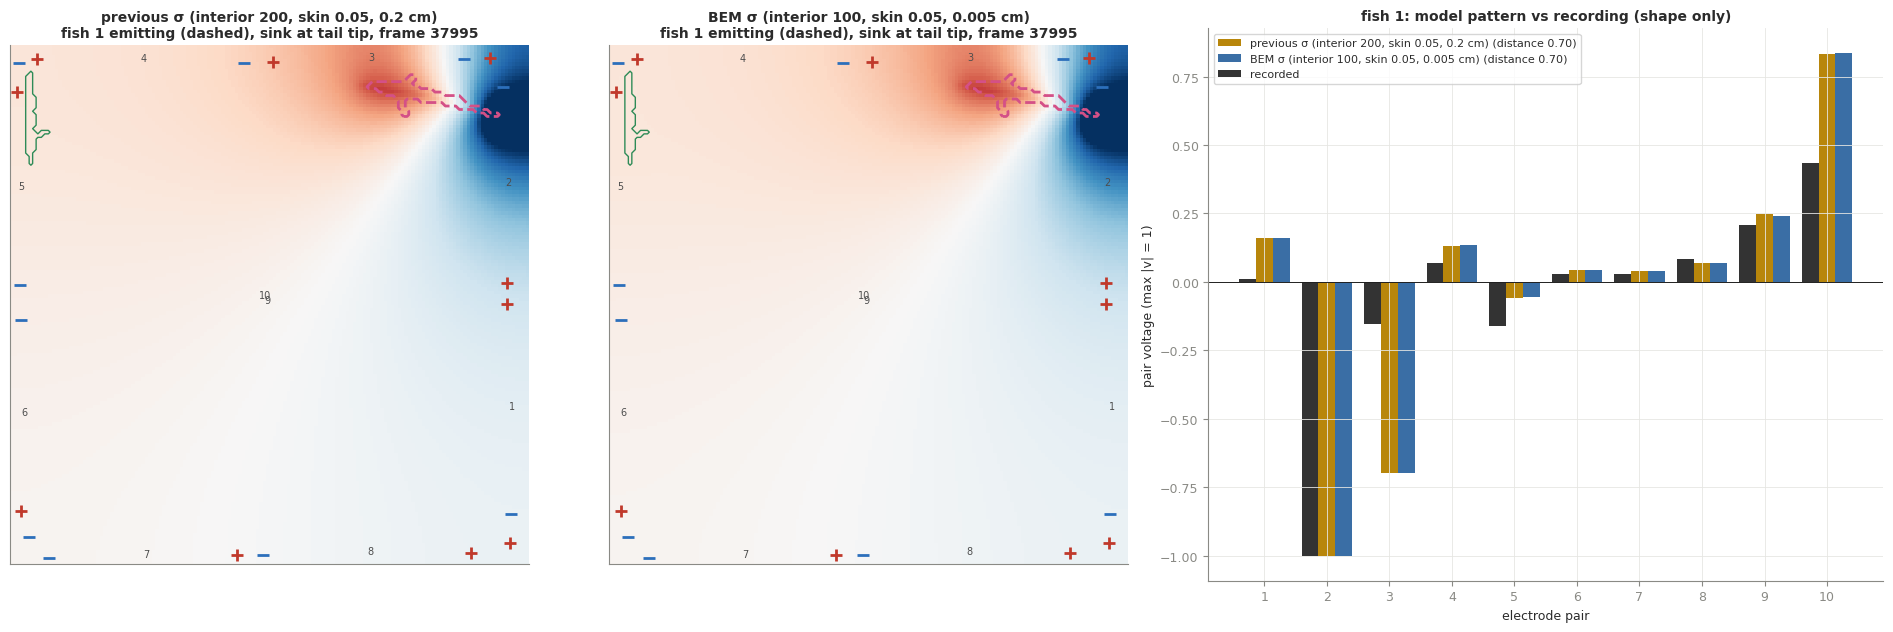

In [4]:
def fish_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords, tail -> head, of every fish; None where the mask is empty or the fit fails.'''
    out = []
    for m in fm:
        try:
            mid = fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] if m.any() else None
            out.append(mid if mid is not None and np.isfinite(mid).all() else None)
        except Exception:
            out.append(None)
    return out

def build_A_fast(occ, N, delta_h, g_water, g_skin, g_interior):
    '''build_A_shell, vectorized: the same matrix, entry for entry (the per-edge weight _edge_weight and the diagonal summed in the
       same order: up, down, left, right neighbour).'''
    tx, ty = theta_outer(occ)
    gnode = np.where(occ > 0.5, g_interior, g_water).astype(complex)
    skin = delta_h * (1 / g_skin - 1 / g_interior)
    def w(gC, gM, thc):                                     # _edge_weight on arrays
        with np.errstate(invalid='ignore'):
            return np.where(np.isnan(thc), gC, 1.0 / (thc / gC + (1 - thc) / gM + skin))
    k = np.arange(N * N).reshape(N, N)                      # flatten_2d_grid: row-major
    W = {'up': w(gnode[1:, :], gnode[:-1, :], 1 - tx), 'down': w(gnode[:-1, :], gnode[1:, :], tx),
         'left': w(gnode[:, 1:], gnode[:, :-1], 1 - ty), 'right': w(gnode[:, :-1], gnode[:, 1:], ty)}
    src = {'up': k[1:, :], 'down': k[:-1, :], 'left': k[:, 1:], 'right': k[:, :-1]}
    dst = {'up': k[:-1, :], 'down': k[1:, :], 'left': k[:, :-1], 'right': k[:, 1:]}
    full = {d: np.zeros((N, N), complex) for d in W}        # each node's weight to each neighbour (0 where there is none)
    full['up'][1:, :], full['down'][:-1, :] = W['up'], W['down']
    full['left'][:, 1:], full['right'][:, :-1] = W['left'], W['right']
    ws = ((0j + full['up']) + full['down']) + full['left'] + full['right']
    r = np.concatenate([src[d].ravel() for d in W] + [k.ravel()])
    c = np.concatenate([dst[d].ravel() for d in W] + [k.ravel()])
    v = np.concatenate([W[d].ravel() for d in W] + [-ws.ravel()])
    return sp.coo_matrix((v, (r, c)), shape=(N * N, N * N), dtype=complex).tocsr()

def solve_sinks(A, bs, pin=0):
    '''solve_potential for several current layouts bs with one LU factorization (same pinned node and gauge); in real arithmetic
       when A is real (omega = 0).'''
    M = (-A).tocsr()
    if not np.any(M.imag.data): M = M.real
    keep = np.ones(M.shape[0]); keep[pin] = 0
    M = (sp.diags(keep) @ M + sp.csr_matrix(([1.0], ([pin], [pin])), shape=M.shape)).tocsc()
    lu = splu(M); out = []
    for b in bs:
        rhs = np.asarray(b).ravel(); rhs = (rhs.real if np.isrealobj(M.data) else rhs.astype(complex)).copy(); rhs[pin] = 0
        phi = lu.solve(rhs); out.append(phi - phi.mean())
    return out

GAM = {n: gammas(0.0, **m) for n, m in MATS.items()}

# example: one good-frame EOD, the emitter emitting (sink at the tail tip), with each set
i_ex = int(np.flatnonzero(GROUPS['good frames'])[3000]); row = df_eod.loc[i_ex]
fm = frame_masks(int(row.Frame)); mids = fish_midlines(fm)
b0 = build_multipole_b(*multipole_sources(mids[EMITTER], I0=1.0, sink_frac=0.0), h, N)
occ_ex = occupancy_field(fm, N, skip=EMITTER)
A_ex = {n: build_A_fast(occ_ex, N, DELTA_H[n], *GAM[n]) for n in MATS}
assert all((A_ex[n] != build_A_shell(occ_ex, N, DELTA_H[n], *GAM[n])).nnz == 0 for n in MATS)          # = build_A_shell, entry for entry
phi_ex = {n: unflatten_to_grid(solve_sinks(A_ex[n], [b0])[0], N).real for n in MATS}
assert all(np.allclose(phi_ex[n], unflatten_to_grid(solve_potential(A_ex[n], b0), N).real, rtol=1e-9, atol=1e-12 * np.abs(phi_ex[n]).max())
           for n in MATS)                                                                     # = solve_potential
r_ex, _ = peak_pattern(recorded_pair_traces(row, pair_ids))

g = np.linspace(0, 1, N)
fig, ax = plt.subplots(1, 3, figsize=(19, 6.4), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
for a, n in zip(ax, MATS):
    v = np.percentile(np.abs(phi_ex[n]), 99)
    a.imshow(phi_ex[n].T, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-v, vmax=v)
    for f in FISH:
        if fm[f].any():
            a.contour(g, g, mask_to_grid(fm[f], N).T.astype(float), levels=[0.5], colors=[FISH_COLOR[f]],
                      linewidths=2 if f == EMITTER else 1, linestyles='--' if f == EMITTER else '-')
    for pid, pp, pm in pairs:
        a.plot(*pp, '+', color='#C0392B', ms=8, mew=2); a.plot(*pm, '_', color='#2C6FBB', ms=8, mew=2)
        a.text(*(0.5 * (pp + pm)), str(pid), fontsize=7, color='0.3')
    a.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xticks=[], yticks=[],
          title=f'{MAT_NAME[n]}\nfish {EMITTER} emitting (dashed), sink at tail tip, frame {int(row.Frame)}')
x, w = np.arange(len(pair_ids)), 0.27
for j, (n, c) in enumerate(zip(MATS, ('#B8860B', '#3A6EA5'))):
    d, vm, vr = compare_patterns(pair_voltages(phi_ex[n], pairs, N), r_ex)
    ax[2].bar(x + j * w, vm, w, color=c, label=f'{MAT_NAME[n]} (distance {d:.2f})')
ax[2].bar(x - w, vr, w, color='0.2', label='recorded')
ax[2].axhline(0, color='k', lw=0.6)
ax[2].set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='pair voltage (max |v| = 1)',
          title=f'fish {EMITTER}: model pattern vs recording (shape only)')
ax[2].legend(fontsize=8, frameon=True, facecolor='white')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/field_example.png', dpi=110); plt.show()

## 3. Model voltages of every EOD

`build_A_fast` is `build_A_shell` vectorized (the same matrix, checked entry for entry in section 2) and `solve_sinks` is
`solve_potential` with one LU for both sinks, in real arithmetic (ω = 0); together about 9 × faster.

For every EOD and each candidate emitter: the conductance matrix with the other fish as a body is built once per set of
conductivities, factorized once, and solved for both sink positions (`multipole_sources(..., sink_frac=s)`: sink −1 at that fraction of
the body length from the tail tip, +1 spread over the points from there to the head), then sampled at the electrodes. A fish
without a mask (or whose midline fit fails) cannot be a candidate (NaN); if that fish is fish 1, the EOD cannot be assigned correctly.
`N_WORKERS` parallel processes; one cache per set of conductivities in `OUT`.

In [5]:
def model_voltages(job):
    '''job = (EOD row i, names of the sets to solve) -> {name: recorded peak pattern and, per sink position, the unit-current pair
       voltages (n_fish, n_pairs), NaN for a fish without a midline}.'''
    i, names = job
    row = df_eod.loc[i]; fm = frame_masks(int(row.Frame)); mids = fish_midlines(fm)
    u = {(n, s): np.full((len(FISH), len(pairs)), np.nan) for n in names for s in SINKS}
    for f in FISH:
        if mids[f] is None: continue
        occ = occupancy_field(fm, N, skip=f)
        bs = [build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=s), h, N) for s in SINKS]
        for n in names:
            for s, phi in zip(SINKS, solve_sinks(build_A_fast(occ, N, DELTA_H[n], *GAM[n]), bs)):
                u[n, s][f] = pair_voltages(unflatten_to_grid(phi, N).real, pairs, N)
    base = dict(row=i, frame=int(row.Frame), time=row.RelativeTime, v_rec=peak_pattern(recorded_pair_traces(row, pair_ids))[0],
                fish_ok=np.array([m is not None for m in mids]))
    return {n: dict(base, **{f'u_sink{s:g}': u[n, s] for s in SINKS}) for n in names}

el_tag = model_cache_tag(N, ELECTRODES_CSV).split('_el')[1]
CACHE = {n: f"{OUT}/model_voltages_N{N}_sinks0and0.05_el{el_tag}_{n}_"
            f"{hashlib.md5(json.dumps(dict(m, delta_h=DELTA_H[n]), sort_keys=True).encode()).hexdigest()[:6]}.pkl" for n, m in MATS.items()}
cols = ['frame', 'time', 'v_rec', 'fish_ok', 'u_sink0', 'u_sink0.05']
caches = {}
for n in MATS:
    caches[n] = pd.read_pickle(CACHE[n]) if os.path.exists(CACHE[n]) else None
need = {n: set(df_eod.index if c is None else df_eod.index.difference(c.index)) for n, c in caches.items()}
jobs = [(i, tuple(n for n in MATS if i in need[n])) for i in df_eod.index]
jobs = [j for j in jobs if j[1]]
print({n: f'{len(df_eod) - len(need[n])} of {len(df_eod)} EODs cached' for n in MATS}, f'-> {len(jobs)} EODs to solve')

def save(caches, out):
    for n, rows in out.items():
        if not rows: continue
        new = pd.DataFrame(rows).set_index('row')[cols]
        caches[n] = new if caches[n] is None else pd.concat([caches[n], new])
        caches[n].to_pickle(CACHE[n])
    return caches, {n: [] for n in MATS}
out = {n: [] for n in MATS}
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:     # forked workers share the loaded masks
    for k, o in enumerate(pool.map(model_voltages, jobs, chunksize=4)):
        for n, d in o.items(): out[n].append(d)
        if (k + 1) % 500 == 0:
            caches, out = save(caches, out); print(f"{k + 1}/{len(jobs)} EODs (cached)")
caches, out = save(caches, out)

res = {n: caches[n].loc[df_eod.index] for n in MATS}
R = np.stack(res['previous'].v_rec)                                                # recorded (n, n_pairs)
assert np.allclose(R, np.stack(res['bem'].v_rec))
U = {(n, s): np.stack(res[n][f'u_sink{s:g}']) for n in MATS for s in SINKS}         # unit-current model (n, n_fish, n_pairs)
fish_ok = np.stack(res['bem'].fish_ok)

# check: one LU for both sinks = eod_assign.candidate_field (its sink: SINK_FRAC = 5% of the body length from the tail tip)
i0 = int(np.flatnonzero(GROUPS['good frames'])[0]); j0 = df_eod.index.get_loc(i0)
fm0 = frame_masks(int(df_eod.Frame[i0])); mids0 = fish_midlines(fm0)
for n in MATS:
    assert np.allclose(U[n, 0.05][j0], [pair_voltages(candidate_field(fm0, f, mids0[f], N, DELTA_H[n], MATS[n]).real, pairs, N)
                                        for f in FISH])
print('check passed: sink 5% = eod_assign.candidate_field, for both sets')
print('EODs with a fish that has no midline:', {f: int((~fish_ok[:, f]).sum()) for f in FISH})

{'previous': '0 of 18770 EODs cached', 'bem': '0 of 18770 EODs cached'} -> 18770 EODs to solve


500/18770 EODs (cached)


1000/18770 EODs (cached)


1500/18770 EODs (cached)


2000/18770 EODs (cached)


2500/18770 EODs (cached)


... (29 outputs left out)

17500/18770 EODs (cached)


18000/18770 EODs (cached)


18500/18770 EODs (cached)


check passed: sink 5% = eod_assign.candidate_field, for both sets
EODs with a fish that has no midline: {0: 153, 1: 5}


## 4. Results

**Rule: shape, sign fixed.** Each fish's 10 model pair voltages times `SIGN` = −1, scaled to max |v| = 1; the recording scaled to max
|v| = 1; L2 distance; the fish with the smallest distance gets the EOD. Fish 1 is the emitter, so % fish 1 = % correct.

Why the sign is fixed: the model has a definite polarity (sink at the tail, sources towards the head), and the recorded pattern is the
sample where |V| peaks, which is always the same (larger) phase of the EOD, because every pair sees the same waveform. So the true
emitter's model matches the recording with the same sign every time. `eod_assign.compare_patterns` (the shape-only rule of the earlier
notebooks) instead lets the sign flip per fish and per EOD, so a fish whose pattern matches only upside down can win.
The sign (−1) was found on the 3-fish recording (`EOD_3fish_examples_BEM_vs_Denis.ipynb`: the emitter's model has the opposite sign
to the recording in 99% of its good-frame EODs), so this recording is an independent test of it. The first table below checks it
here; the sign-free rule is reported once for reference.

In [6]:
SIGN = -1                                        # model x SIGN matches the recorded peak pattern

def shape_assign(M, sign=SIGN):
    '''Model voltages M (n, n_fish, n_pairs) times `sign`, and the recording, each scaled to max |v| = 1; L2 distance; the smallest
       wins. sign=None: the sign is free per fish (compare_patterns, the earlier shape-only rule). A fish with NaN voltages (no
       midline) cannot win. Returns (fish (n,), distances (n, n_fish)).'''
    a = M / np.abs(M).max(axis=2, keepdims=True); r = R / np.abs(R).max(axis=1, keepdims=True)
    if sign is None:
        D = np.minimum(np.linalg.norm(a - r[:, None], axis=2), np.linalg.norm(a + r[:, None], axis=2))
    else:
        D = np.linalg.norm(sign * a - r[:, None], axis=2)
    D = np.where(np.isfinite(D), D, np.inf)
    return D.argmin(axis=1), D

j0 = int(np.flatnonzero(fish_ok.all(axis=1))[0])          # sign-free version = compare_patterns
assert np.allclose(shape_assign(U['previous', 0.0][j0:j0 + 1], None)[1][0],
                   [compare_patterns(m, R[j0])[0] for m in U['previous', 0.0][j0]])

# check of the sign on all EODs: sign of the emitter's model relative to the recording
opp = {(n, s): np.einsum('np,np->n', U[n, s][:, EMITTER], R) < 0 for n in MATS for s in SINKS}
display(pd.DataFrame({g: {f'{MAT_NAME[n]}, {SINK_NAME[s]}': 100 * np.nanmean(opp[n, s][m & fish_ok[:, EMITTER]])
                          for n in MATS for s in SINKS} for g, m in GROUPS.items()}).round(2)
        .rename_axis(f"% EODs where fish {EMITTER}'s model has the opposite sign to the recording"))

assigned = df_eod[['Frame', 'RelativeTime']].copy()
for g, m in GROUPS.items(): assigned[g] = m
VARIANTS = {}
for n in MATS:
    for s in SINKS:
        name = f'{MAT_NAME[n]}, {SINK_NAME[s]}'; VARIANTS[name] = (n, s)
        fish, D = shape_assign(U[n, s])
        assigned[f'fish | {name}'] = fish
        for f in FISH: assigned[f'distance fish {f} | {name}'] = D[:, f]
DENIS = "Denis' pipeline (latest run)"
assigned[f'fish | {DENIS}'] = denis['discharging_fish'].map({'A': 1, 'B': 0}).to_numpy()   # A/B by length: A = larger = fish 1
fish_cols = [c for c in assigned.columns if c.startswith('fish |')]
names = [c.replace('fish | ', '') for c in fish_cols]

acc = pd.DataFrame({g: [100 * (assigned.loc[m, c] == EMITTER).mean() for c in fish_cols] for g, m in GROUPS.items()}, index=names)
acc.columns = [f'{g} (n = {GROUPS[g].sum()})' for g in GROUPS]
acc.index.name = f'% correct (fish {EMITTER})'
acc.to_csv(f'{OUT}/accuracy_by_group.csv')
display(acc.round(2))

free = pd.DataFrame({g: {f'{MAT_NAME[n]}, {SINK_NAME[s]}, sign free': 100 * (shape_assign(U[n, s], None)[0][m] == EMITTER).mean()
                         for n in MATS for s in SINKS} for g, m in GROUPS.items()})
free.columns = acc.columns
display(free.round(2).rename_axis('for reference: % correct with the sign free (earlier shape-only rule)'))
free.to_csv(f'{OUT}/accuracy_by_group_sign_free.csv')

split = pd.concat({g: pd.DataFrame({nm: assigned.loc[m, c].value_counts(normalize=True).reindex(FISH, fill_value=0) * 100
                                     for c, nm in zip(fish_cols, names)}).T.rename(columns=FISH_NAME)
                   for g, m in GROUPS.items()}, names=['group', 'pipeline'])
split.to_csv(f'{OUT}/assignment_fractions_by_group.csv')
display(split.round(2))
assigned.to_csv(f'{OUT}/eod_assignments.csv', index_label='row')
print(f"saved {OUT}/accuracy_by_group.csv, assignment_fractions_by_group.csv, eod_assignments.csv")

,all EODs,mask-QC good,SLEAP-good,good frames
% EODs where fish 1's model has the opposite sign to the recording,,,,
"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip",94.53,97.05,96.07,97.34
"previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip",93.20,95.84,95.06,96.66
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip",94.48,97.05,96.07,97.31
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip",93.15,95.83,95.08,96.69


,all EODs (n = 18770),mask-QC good (n = 12121),SLEAP-good (n = 4430),good frames (n = 3532)
% correct (fish 1),,,,
"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip",93.56,96.03,95.42,96.60
"previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip",92.31,94.75,94.02,95.27
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip",93.65,96.06,95.53,96.63
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip",92.33,94.74,94.02,95.16
Denis' pipeline (latest run),89.75,94.04,94.58,95.87


,all EODs (n = 18770),mask-QC good (n = 12121),SLEAP-good (n = 4430),good frames (n = 3532)
for reference: % correct with the sign free (earlier shape-only rule),,,,
"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip, sign free",91.06,94.97,94.83,96.01
"previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip, sign free",90.25,94.07,93.95,94.82
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip, sign free",91.33,95.00,94.99,95.98
"BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip, sign free",90.35,94.07,94.04,94.79


fish 0 (smaller, silent)  \
group        pipeline                                                                       
all EODs     previous σ (interior 200, skin 0.05, 0.2 cm), s...                      6.44   
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                      7.69   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      6.35   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      7.67   
             Denis' pipeline (latest run)                                           10.25   
mask-QC good previous σ (interior 200, skin 0.05, 0.2 cm), s...                      3.97   
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                      5.25   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      3.94   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      5.26   
             Denis' pipeline (latest run)                                            5.96   
SLEAP-good   previous σ (interior 200, skin 0.05, 0.2 cm), s...                      4.58   
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                      5.98   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      4.47   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      5.98   
             Denis' pipeline (latest run)                                            5.42   
good frames  previous σ (interior 200, skin 0.05, 0.2 cm), s...                      3.40   
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                      4.73   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      3.37   
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                      4.84   
             Denis' pipeline (latest run)                                            4.13   

                                                                 fish 1 (larger, emitter)  
group        pipeline                                                                      
all EODs     previous σ (interior 200, skin 0.05, 0.2 cm), s...                     93.56  
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                     92.31  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     93.65  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     92.33  
             Denis' pipeline (latest run)                                           89.75  
mask-QC good previous σ (interior 200, skin 0.05, 0.2 cm), s...                     96.03  
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                     94.75  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     96.06  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     94.74  
             Denis' pipeline (latest run)                                           94.04  
SLEAP-good   previous σ (interior 200, skin 0.05, 0.2 cm), s...                     95.42  
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                     94.02  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     95.53  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     94.02  
             Denis' pipeline (latest run)                                           94.58  
good frames  previous σ (interior 200, skin 0.05, 0.2 cm), s...                     96.60  
             previous σ (interior 200, skin 0.05, 0.2 cm), s...                     95.27  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     96.63  
             BEM σ (interior 100, skin 0.05, 0.005 cm), sink...                     95.16  
             Denis' pipeline (latest run)                                           95

saved results/eod_ground_truth/conductivities/accuracy_by_group.csv, assignment_fractions_by_group.csv, eod_assignments.csv


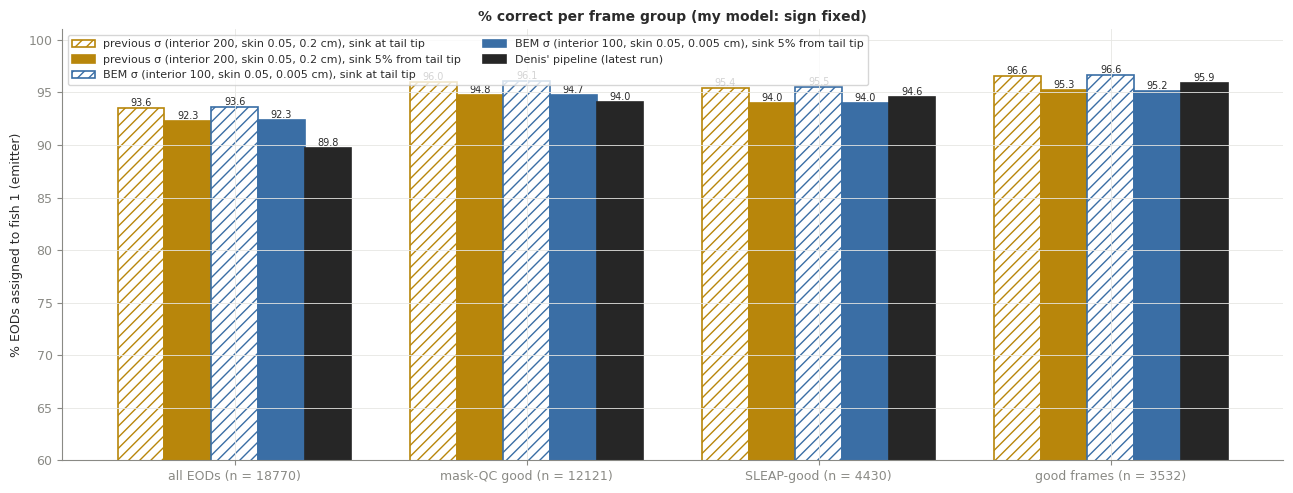

In [7]:
STYLE = {names[0]: ('#B8860B', 'o', ':'), names[1]: ('#B8860B', 'o', '-'), names[2]: ('#3A6EA5', 's', ':'),
         names[3]: ('#3A6EA5', 's', '-'), names[4]: ('0.15', 'D', '-')}
fig, ax = plt.subplots(figsize=(13, 5))
x, w = np.arange(len(GROUPS)), 0.16
for j, nm in enumerate(names):
    col, _, ls = STYLE[nm]
    bars = ax.bar(x + (j - 2) * w, acc.loc[nm], w, color=col if ls == '-' else 'white', edgecolor=col, hatch=None if ls == '-' else '///',
                  lw=1.2, label=nm)
    ax.bar_label(bars, fmt='%.1f', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(acc.columns)
ax.set(ylabel=f'% EODs assigned to fish {EMITTER} (emitter)', ylim=(60, 101), title='% correct per frame group (my model: sign fixed)')
ax.legend(fontsize=8, loc='upper left', frameon=True, facecolor='white', ncol=2)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_by_group.png', dpi=110); plt.show()

### Agreement with Denis

EODs in each group, by which of the two pipelines is right: the best of my four variants on all EODs vs Denis' latest run.

In [8]:
best = acc.iloc[:4, 0].idxmax(); cb, cd = f'fish | {best}', f'fish | {DENIS}'
print('best of my variants on all EODs:', best)
ok_b, ok_d = assigned[cb] == EMITTER, assigned[cd] == EMITTER
tab = pd.DataFrame({g: {'both right': (ok_b & ok_d)[m].sum(), 'only mine right': (ok_b & ~ok_d)[m].sum(),
                        "only Denis' right": (~ok_b & ok_d)[m].sum(), 'both wrong': (~ok_b & ~ok_d)[m].sum()}
                    for g, m in GROUPS.items()}).T
display(tab)

best of my variants on all EODs: BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip


,both right,only mine right,only Denis' right,both wrong
all EODs,16441,1137,406,786
mask-QC good,11275,368,124,354
SLEAP-good,4134,98,56,142
good frames,3358,55,28,91


### % correct against the distance between the emitter and the other fish

Distance = smallest distance (cm, mask edge to edge) between the two fish in the EOD's frame (NaN if a mask is missing); 10 bins with
equal numbers of EODs; error bars: 95% Wilson interval.

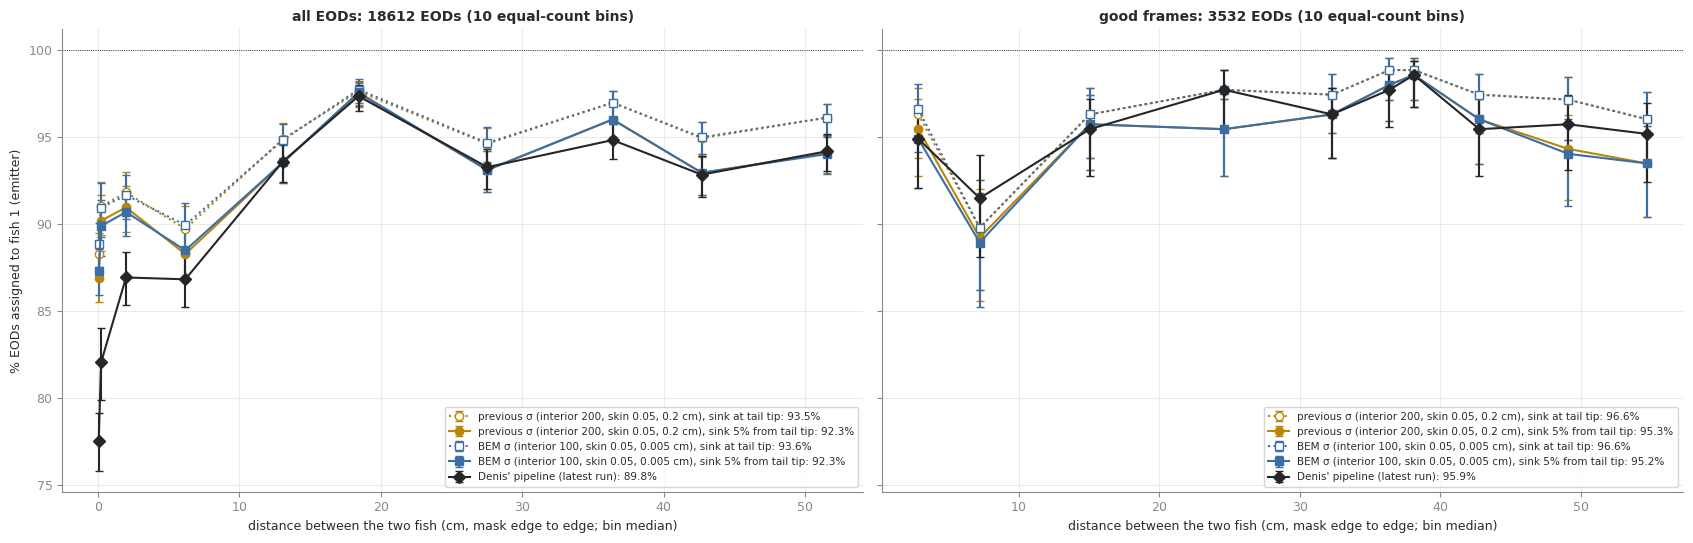

all EODs


,"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip","previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip","BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip","BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip",Denis' pipeline (latest run)
median gap (cm),,,,,
0.1,88.3,86.9,88.9,87.3,77.5
0.2,91.0,90.2,91.0,89.9,82.1
2.0,91.8,91.0,91.7,90.7,86.9
6.2,89.7,88.3,90.0,88.5,86.8
13.1,94.9,93.6,94.8,93.6,93.6
18.4,97.6,97.5,97.7,97.6,97.4
27.5,94.6,93.1,94.7,93.1,93.3
36.4,97.0,96.0,97.0,96.0,94.8
42.7,94.9,93.0,95.0,93.0,92.9


good frames


,"previous σ (interior 200, skin 0.05, 0.2 cm), sink at tail tip","previous σ (interior 200, skin 0.05, 0.2 cm), sink 5% from tail tip","BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip","BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip",Denis' pipeline (latest run)
median gap (cm),,,,,
2.9,96.3,95.5,96.6,94.9,94.9
7.2,89.8,89.2,89.8,89.0,91.5
15.1,96.3,95.8,96.3,95.8,95.5
24.6,97.7,95.5,97.7,95.5,97.7
32.3,97.5,96.3,97.5,96.3,96.3
36.4,98.9,98.0,98.9,98.0,97.7
38.1,98.9,98.6,98.9,98.6,98.6
42.8,97.5,96.0,97.5,96.0,95.5
49.1,97.2,94.3,97.2,94.1,95.8


In [9]:
def gap_to_others(k):
    '''Smallest distance (px) between the mask of the emitter and the mask of the other fish in frame k (NaN if one is missing).'''
    fm = frame_masks(k)
    if not fm[EMITTER].any(): return np.nan
    t = cKDTree(np.argwhere(fm[EMITTER]))
    d = [t.query(np.argwhere(fm[f]))[0].min() for f in FISH if f != EMITTER and fm[f].any()]
    return min(d) if d else np.nan

uf = assigned.Frame.unique()
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
    gap = dict(zip(uf, pool.map(gap_to_others, [int(k) for k in uf], chunksize=64)))
assigned['gap_cm'] = assigned.Frame.map(gap) / PX_PER_CM
assigned.to_csv(f'{OUT}/eod_assignments.csv', index_label='row')

def wilson(k, m, z=1.96):
    '''95% Wilson interval of k successes in m trials, in %.'''
    p = k / m; c = (p + z ** 2 / (2 * m)) / (1 + z ** 2 / m); hw = z * np.sqrt(p * (1 - p) / m + z ** 2 / (4 * m ** 2)) / (1 + z ** 2 / m)
    return 100 * (c - hw), 100 * (c + hw)

fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
tables = {}
for a, g in zip(axs, ('all EODs', 'good frames')):
    sub = assigned[assigned[g] & assigned.gap_cm.notna()]
    bins = pd.qcut(sub.gap_cm, 10); curves = {}
    for c, nm in zip(fish_cols, names):
        gr = sub.groupby(bins, observed=True)
        t = pd.DataFrame({'median gap (cm)': gr.gap_cm.median(), 'n': gr.size(), 'k': gr[c].apply(lambda s: (s == EMITTER).sum())})
        t['pct'] = 100 * t.k / t.n; lo, hi = wilson(t.k, t.n); curves[nm] = t.pct.to_numpy()
        col, mk, ls = STYLE[nm]
        a.errorbar(t['median gap (cm)'], t.pct, yerr=[t.pct - lo, hi - t.pct], fmt=mk, ls=ls, color=col, mfc=col if ls == '-' else 'white',
                   capsize=3, label=f"{nm}: {100 * (sub[c] == EMITTER).mean():.1f}%")
    tables[g] = pd.DataFrame(curves, index=pd.Index(t['median gap (cm)'].round(1).to_numpy(), name='median gap (cm)')).round(1)
    a.axhline(100, color='k', lw=0.6, ls=':')
    a.set(xlabel='distance between the two fish (cm, mask edge to edge; bin median)',
          title=f'{g}: {len(sub)} EODs (10 equal-count bins)')
    a.legend(fontsize=7.5, loc='lower right', frameon=True, facecolor='white')
axs[0].set_ylabel(f'% EODs assigned to fish {EMITTER} (emitter)')
plt.tight_layout(); fig.savefig(f'{OUT}/figures/correct_vs_distance.png', dpi=110); plt.show()
for g, t in tables.items(): print(g); display(t)

### Over the recording

% of EODs assigned to fish 1 in 30 time bins with equal numbers of EODs (all EODs), with the % of EODs in good frames per bin.

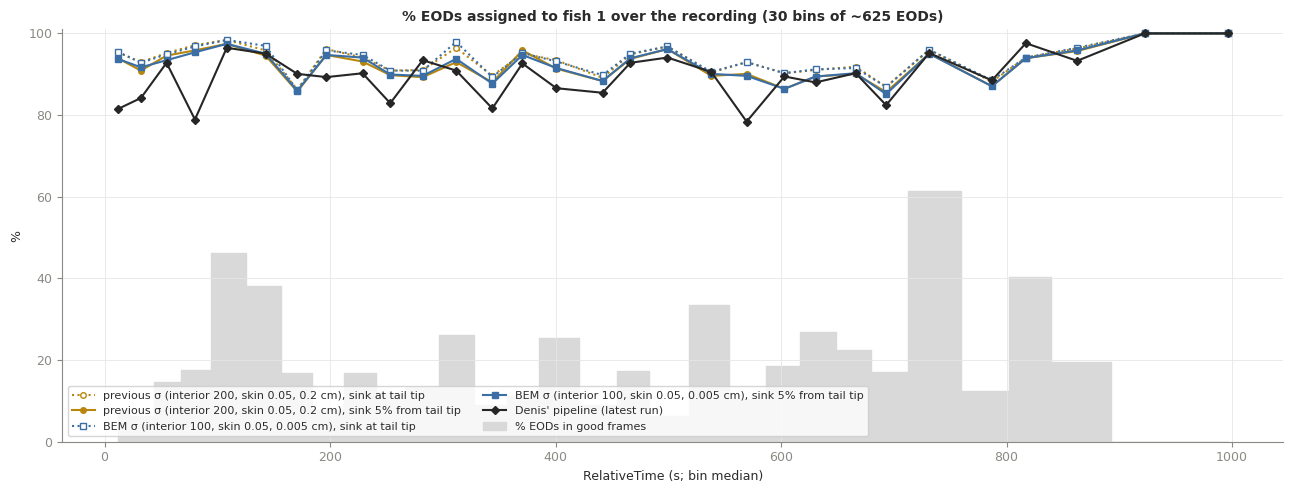

In [10]:
tb = pd.qcut(assigned.RelativeTime, 30)
fig, ax = plt.subplots(figsize=(13, 5))
gr = assigned.groupby(tb, observed=True)
for c, nm in zip(fish_cols, names):
    col, mk, ls = STYLE[nm]
    ax.plot(gr.RelativeTime.median(), 100 * gr[c].apply(lambda s: (s == EMITTER).mean()), marker=mk, ls=ls, color=col, ms=4,
            mfc=col if ls == '-' else 'white', label=nm)
ax.fill_between(gr.RelativeTime.median(), 0, 100 * gr['good frames'].mean(), color='0.85', step='mid', label='% EODs in good frames')
ax.set(xlabel='RelativeTime (s; bin median)', ylabel='%', ylim=(0, 101),
       title=f'% EODs assigned to fish {EMITTER} over the recording (30 bins of ~{len(assigned) // 30} EODs)')
ax.legend(fontsize=8, loc='lower left', frameon=True, facecolor='white', ncol=2)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_over_time.png', dpi=110); plt.show()

## 5. Summary

All 18,770 EODs; emitter fish 1. My model: sign fixed (model × −1, found on the 3-fish recording), patterns scaled to max |v| = 1, L2
distance. % correct:

| pipeline | all EODs (18,770) | mask-QC good (12,121) | SLEAP-good (4,430) | good frames (3,532) |
|---|---|---|---|---|
| previous σ, sink at tail tip | 93.56 | 96.03 | 95.42 | 96.60 |
| previous σ, sink 5% from tail tip | 92.31 | 94.75 | 94.02 | 95.27 |
| **BEM σ (0.005 cm skin), sink at tail tip** | **93.65** | **96.06** | **95.53** | **96.63** |
| BEM σ (0.005 cm skin), sink 5% from tail tip | 92.33 | 94.74 | 94.02 | 95.16 |
| Denis' latest run | 89.75 | 94.04 | 94.58 | 95.87 |
| *reference: BEM σ, tail tip, sign free* | *91.33* | *95.00* | *94.99* | *95.98* |

- **Sign**: the sign found on the 3-fish recording holds here too: fish 1's model has the opposite sign to the recording in 97% of
  good-frame EODs and 94.5% of all EODs; fixing it adds 0.6 (good frames) to 2.3 (all EODs) points.
- **Conductivities**: the BEM set and the previous set give the same accuracy (within 0.1 points).
- **Sink**: at the tail tip is better than 5% in, in every group (by 1.2–1.5 points).
- **Against Denis**: mine (BEM σ, tail tip) is higher in every group: +3.9 points on all EODs, +0.8 on good frames. On all EODs,
  1,137 EODs are right only by mine and 406 only by Denis; on good frames 55 and 28. The gain on all EODs comes mostly from frames
  where the fish are within ~6 cm (87–91% vs 78–87% for Denis).
- 5 EODs have no mask of fish 1 and count as wrong for my model.
